Imports:

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

device = "cuda" if torch.cuda.is_available() else "cpu"

Definindo modelo:

In [2]:
class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(2,64),
            nn.Tanh(),

            nn.Linear(64,64),
            nn.Tanh(),

            nn.Linear(64,64),
            nn.Tanh(),

            nn.Linear(64,1)
        )

    def forward(self,x,t):

        inp = torch.cat([x,t],dim=1)
        return self.net(inp)

model = PINN().to(device)

Construindo dataset:

In [3]:
############################################################
# Pontos internos
############################################################

N_f = 5000

x_f = torch.rand(N_f,1,device=device,requires_grad=True)
t_f = torch.rand(N_f,1,device=device,requires_grad=True)

############################################################
# Condição inicial
############################################################

N0 = 300

x0 = torch.rand(N0,1,device=device)

t0 = torch.zeros_like(x0)

u0 = torch.sin(np.pi*x0)

############################################################
# Contorno esquerdo
############################################################

Nb = 300

tb = torch.rand(Nb,1,device=device)

xb_left = torch.zeros_like(tb)

ub_left = torch.zeros_like(tb)
#ub_left = torch.ones_like(tb)

############################################################
# Contorno direito
############################################################

xb_right = torch.ones_like(tb)

ub_right = torch.zeros_like(tb)

Treinando:

In [4]:
optimizer = torch.optim.Adam(model.parameters(),lr=1e-3)

epochs = 5000

for epoch in range(epochs):

    optimizer.zero_grad()

    #####################################
    # Física
    #####################################

    u = model(x_f,t_f)

    u_t = torch.autograd.grad(
        u,
        t_f,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = torch.autograd.grad(
        u,
        x_f,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x,
        x_f,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    residual = u_t - u_xx

    loss_pde = torch.mean(residual**2)

    #####################################
    # Condição inicial
    #####################################

    pred0 = model(x0,t0)

    loss_ic = torch.mean((pred0-u0)**2)

    #####################################
    # Contorno
    #####################################

    pred_left = model(xb_left,tb)

    pred_right = model(xb_right,tb)

    loss_bc = torch.mean((pred_left-ub_left)**2) + \
              torch.mean((pred_right-ub_right)**2)

    #####################################

    loss = loss_pde + loss_ic + loss_bc

    loss.backward()

    optimizer.step()

    if epoch%500==0:

        print(f'Época: {epoch} - Loss: {loss.item()}')

/home/lorrantwo/Documentos/GitHub/LNCC/Doutorado/Disciplinas/03-Topicos-avancados-redes-neurais-profundas/PINN/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:979: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:408.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Época: 0 - Loss: 0.6377097964286804
Época: 500 - Loss: 0.007939652539789677
Época: 1000 - Loss: 0.0005035054055042565
Época: 1500 - Loss: 0.008320994675159454
Época: 2000 - Loss: 0.00013091068831272423
Época: 2500 - Loss: 0.00010003932402469218
Época: 3000 - Loss: 0.0001227125758305192
Época: 3500 - Loss: 6.37979173916392e-05
Época: 4000 - Loss: 0.0008266757358796895
Época: 4500 - Loss: 4.707810148829594e-05


Avaliando:

In [5]:
############################################################
# Avaliação
############################################################

x = np.linspace(0,1,100)
t = np.linspace(0,1,100)

X,T = np.meshgrid(x,t)

XT = torch.tensor(
    np.stack([X.flatten(),T.flatten()],axis=1),
    dtype=torch.float32,
    device=device
)

with torch.no_grad():

    pred = model(
        XT[:,0:1],
        XT[:,1:2]
    )

U = pred.cpu().numpy().reshape(100,100)

############################################################
# Solução exata
############################################################

U_exact = np.exp(-np.pi**2*T)*np.sin(np.pi*X)

# import numpy as np

# # -----------------------------------------------------
# # Coeficientes de Fourier
# # -----------------------------------------------------

# def compute_bn(n, Nint=5000):

#     x = np.linspace(0,1,Nint)

#     f = np.sin(np.pi*x) - (1-x)

#     integrand = f*np.sin(n*np.pi*x)

#     return 2*np.trapezoid(integrand, x)


# # quantidade de termos da série
# N_terms = 100

# bn = np.array([
#     compute_bn(n)
#     for n in range(1,N_terms+1)
# ])

# # -----------------------------------------------------
# # Solução analítica
# # -----------------------------------------------------

# U_exact = 1 - X

# for n in range(1,N_terms+1):

#     U_exact += (
#         bn[n-1]
#         * np.exp(-(n*np.pi)**2*T)
#         * np.sin(n*np.pi*X)
#     )

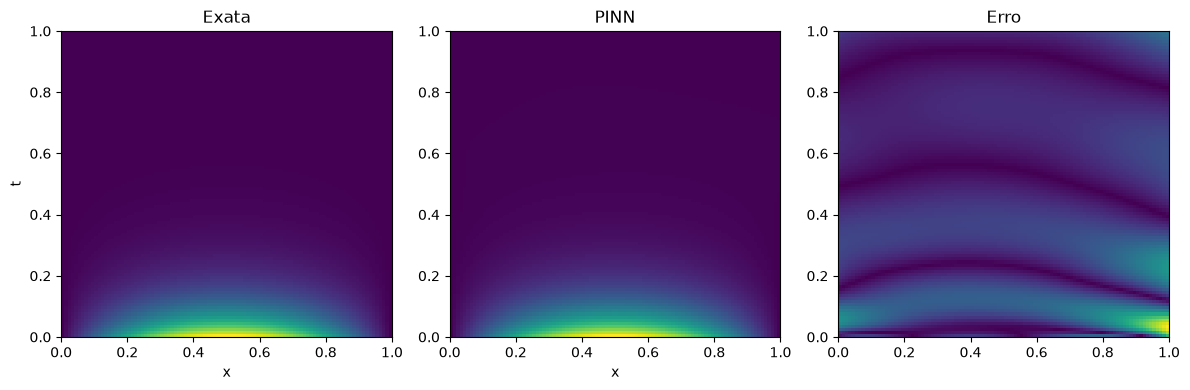

In [6]:
########################################################################################################################
# Solução exata
############################################################

#U_exact = np.exp(-np.pi**2*T)*np.sin(np.pi*X)
# Resultados
############################################################

plt.figure(figsize=(12,4))

plt.subplot(131)
plt.imshow(U_exact,
           origin="lower",
           extent=[0,1,0,1],
           aspect="auto")
plt.title("Exata")
plt.xlabel("x")
plt.ylabel("t")

plt.subplot(132)
plt.imshow(U,
           origin="lower",
           extent=[0,1,0,1],
           aspect="auto")
plt.title("PINN")
plt.xlabel("x")

plt.subplot(133)
plt.imshow(np.abs(U-U_exact),
           origin="lower",
           extent=[0,1,0,1],
           aspect="auto")
plt.title("Erro")

plt.tight_layout()
plt.show()